# Notebook 2 : estimation des paramètres (Brent, puis crack spread)

Le 1er janvier, une banque qui vend une option doit choisir ses paramètres sans connaître l'année qui commence. On compare des estimateurs (historique, EWMA) à ce qui s'est réellement passé ensuite.

- Parties 1 et 2 : la vol du Brent, pour le call.
- Partie 3 : les trois paramètres du crack spread $42 \cdot \text{HO} - \text{CL}$ (vol du fioul, vol du WTI, corrélation ρ), pour l'option sur spread.

## 0. Données

Prix de clôture quotidiens du Brent (`BZ=F`) de 2012 à 2024, avec `get_prices`. On commence en 2012 pour pouvoir estimer σ dès le 1er janvier 2013 à partir de l'année 2012.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from spread_options.data import get_prices
from spread_options.volatility import historical_vol, ewma_vol

prices = get_prices("BZ=F", "01/01/2012", "31/12/2024")
print(f"{len(prices)} prix, du {prices.index[0].date()} au {prices.index[-1].date()}")

3251 prix, du 2012-01-03 au 2024-12-31


## 1. Vol historique : estimé contre réalisé

Pour chaque année $y$ de 2013 à 2024 :

$$\sigma^{\text{est}}_y = \text{vol de l'année } y-1 \quad(\text{connue le 1er janvier}) \qquad \sigma^{\text{réal}}_y = \text{vol de l'année } y \quad(\text{connue le 31 décembre})$$

$$\text{erreur}_y = \sigma^{\text{est}}_y - \sigma^{\text{réal}}_y$$

Une erreur positive veut dire qu'on a surestimé la vol, une erreur négative qu'on l'a sous-estimée.

On résume les douze erreurs de deux façons. Dans l'erreur moyenne, les erreurs positives et négatives se compensent : elle dit si l'on se trompe toujours dans le même sens (un biais). Dans l'erreur absolue moyenne, on enlève les signes avant de faire la moyenne : elle dit de combien on se trompe en général.

In [2]:
years = list(range(2013, 2025)) # 2013, ..., 2024 (range excludes 2025)
sigma_est = [] # what the bank knows on January 1st
sigma_real = [] # what really happened during the year
for year in years:
    # prices["2012"] (text) = every date of 2012; prices[2012] (number) would be the 2013th price
    sigma_est.append(historical_vol(prices[str(year - 1)])) # vol of the PREVIOUS year
    sigma_real.append(historical_vol(prices[str(year)])) # vol of THIS year, known only at the end
sigma_est = np.array(sigma_est) # lists -> arrays, to subtract them element by element
sigma_real = np.array(sigma_real)
errors = sigma_est - sigma_real # > 0: overestimated, < 0: underestimated

for year, est, real, err in zip(years, sigma_est, sigma_real, errors): # walk the 4 lists together
    print(f"{year} | estimé {est:.1%} | réalisé {real:.1%} | erreur {err * 100:+.1f} pts")
print() # empty line
print(f"erreur moyenne {errors.mean() * 100:+.1f} pts | erreur absolue moyenne {np.abs(errors).mean() * 100:.1f} pts")

2013 | estimé 23.2% | réalisé 16.8% | erreur +6.5 pts
2014 | estimé 16.8% | réalisé 20.7% | erreur -3.9 pts
2015 | estimé 20.7% | réalisé 44.1% | erreur -23.5 pts
2016 | estimé 44.1% | réalisé 45.0% | erreur -0.9 pts
2017 | estimé 45.0% | réalisé 24.0% | erreur +21.1 pts
2018 | estimé 24.0% | réalisé 30.6% | erreur -6.7 pts
2019 | estimé 30.6% | réalisé 31.4% | erreur -0.7 pts
2020 | estimé 31.4% | réalisé 71.4% | erreur -40.0 pts
2021 | estimé 71.4% | réalisé 32.5% | erreur +38.9 pts
2022 | estimé 32.5% | réalisé 46.6% | erreur -14.1 pts
2023 | estimé 46.6% | réalisé 31.7% | erreur +14.9 pts
2024 | estimé 31.7% | réalisé 26.5% | erreur +5.2 pts

erreur moyenne -0.3 pts | erreur absolue moyenne 14.7 pts


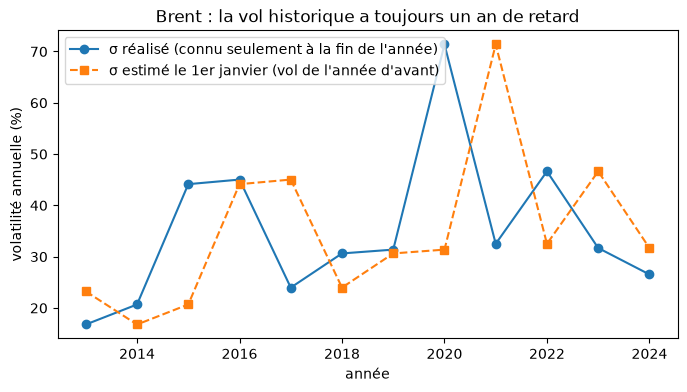

In [3]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(years, sigma_real * 100, "o-", label="σ réalisé (connu seulement à la fin de l'année)") # o- = dots + line
ax.plot(years, sigma_est * 100, "s--", label="σ estimé le 1er janvier (vol de l'année d'avant)") # s-- = squares + dashes
ax.set_xlabel("année")
ax.set_ylabel("volatilité annuelle (%)")
ax.set_title("Brent : la vol historique a toujours un an de retard")
ax.legend()
plt.show()

### Lecture

La courbe estimée est la courbe réalisée décalée d'un an : l'estimateur rate les hausses de vol (2015, 2020, 2022) et surréagit l'année suivante (2017, 2021, 2023).

L'erreur moyenne est proche de 0, il n'y a donc pas de biais, mais l'erreur typique est de 14,7 points. Si la vol était constante, un an de données la donnerait à 0,9 point près (`test_volatility.py`) : la vol du Brent change d'une année à l'autre.

## 2. EWMA : estimé contre réalisé

La vol historique donne le même poids aux 252 jours de l'année. L'EWMA met à jour son estimation chaque soir :

$$\sigma^2_t = \lambda\,\sigma^2_{t-1} + (1-\lambda)\,r_t^2, \qquad \lambda = 0{,}94$$

En français : la nouvelle variance garde 94 % de celle de la veille et prend 6 % du rendement du jour au carré. Un rendement vieux de $k$ jours pèse donc $0{,}06 \times 0{,}94^k$ : 6 % le jour même, 3 % au bout de 11 jours, presque rien après trois mois. L'EWMA au 31 décembre mesure surtout la vol des dernières semaines.

On garde la même grille que dans la partie 1. Seule l'estimation change :

$$\sigma^{\text{est}}_y = \text{EWMA au 31 décembre de l'année } y-1 \qquad \sigma^{\text{réal}}_y = \text{vol de l'année } y \ (\text{inchangée})$$

`ewma_vol` démarre avec le premier rendement de l'année $y-1$ au carré. Ce point de départ a environ 250 jours d'ancienneté au 31 décembre, son poids vaut $0{,}94^{250} \approx 2 \times 10^{-7}$, donc il ne change pas le résultat.

In [4]:
sigma_ewma = [] # EWMA at December 31st of the previous year
for year in years:
    sigma_ewma.append(ewma_vol(prices[str(year - 1)])) # only the prices of year-1: known on January 1st
sigma_ewma = np.array(sigma_ewma)
errors_ewma = sigma_ewma - sigma_real # same realized vol as in part 1

for year, est, real, err in zip(years, sigma_ewma, sigma_real, errors_ewma):
    print(f"{year} | estimé {est:.1%} | réalisé {real:.1%} | erreur {err * 100:+.1f} pts")
print()
print(f"erreur moyenne {errors_ewma.mean() * 100:+.1f} pts | erreur absolue moyenne {np.abs(errors_ewma).mean() * 100:.1f} pts")

# same summary without 2020 (Covid): True for every year except 2020
not_2020 = np.array(years) != 2020
print(f"sans 2020 : erreur moyenne {errors_ewma[not_2020].mean() * 100:+.1f} pts"
      f" | erreur absolue moyenne {np.abs(errors_ewma[not_2020]).mean() * 100:.1f} pts"
      f" (vol historique : {np.abs(errors[not_2020]).mean() * 100:.1f} pts)")

2013 | estimé 18.0% | réalisé 16.8% | erreur +1.2 pts
2014 | estimé 14.4% | réalisé 20.7% | erreur -6.3 pts
2015 | estimé 37.1% | réalisé 44.1% | erreur -7.0 pts
2016 | estimé 39.6% | réalisé 45.0% | erreur -5.5 pts
2017 | estimé 35.2% | réalisé 24.0% | erreur +11.2 pts
2018 | estimé 20.4% | réalisé 30.6% | erreur -10.3 pts
2019 | estimé 56.5% | réalisé 31.4% | erreur +25.1 pts
2020 | estimé 24.1% | réalisé 71.4% | erreur -47.3 pts
2021 | estimé 26.4% | réalisé 32.5% | erreur -6.1 pts
2022 | estimé 37.4% | réalisé 46.6% | erreur -9.2 pts
2023 | estimé 37.2% | réalisé 31.7% | erreur +5.5 pts
2024 | estimé 32.0% | réalisé 26.5% | erreur +5.5 pts

erreur moyenne -3.6 pts | erreur absolue moyenne 11.7 pts
sans 2020 : erreur moyenne +0.4 pts | erreur absolue moyenne 8.4 pts (vol historique : 12.4 pts)


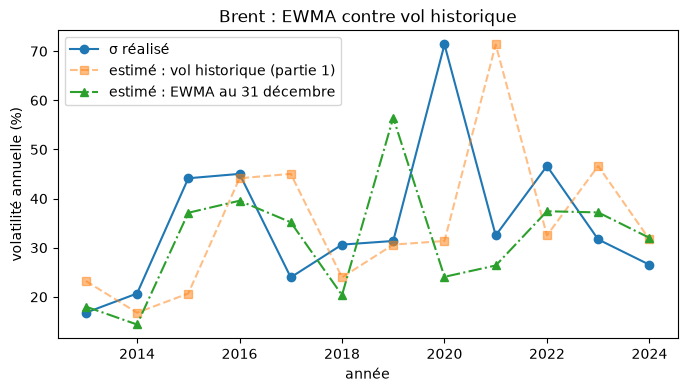

In [5]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(years, sigma_real * 100, "o-", label="σ réalisé")
ax.plot(years, sigma_est * 100, "s--", alpha=0.5, label="estimé : vol historique (partie 1)") # alpha: lighter
ax.plot(years, sigma_ewma * 100, "^-.", label="estimé : EWMA au 31 décembre") # ^-. = triangles + dash-dots
ax.set_xlabel("année")
ax.set_ylabel("volatilité annuelle (%)")
ax.set_title("Brent : EWMA contre vol historique")
ax.legend()
plt.show()

### Lecture

L'EWMA ne traîne plus le pic du Covid : il donne 26 % pour 2021 (réalisé 32,5 %) au lieu de 71 %. L'erreur absolue moyenne passe de 14,7 à 11,7 points, et sans 2020 (imprévisible fin 2019) de 12,4 à 8,4 points, sans biais.

Son défaut : il prédit une année entière avec les dernières semaines. Fin 2018, le Brent chute de 40 % en trois mois, et l'EWMA annonce 56 % pour une année 2019 calme (31 %).

## 3. Le crack spread : σ du fioul, σ du WTI et ρ

Le crack spread est la marge du raffineur : $42 \times \text{HO} - \text{CL}$. Le fioul (`HO=F`) est coté en \$ par gallon, et un baril contient 42 gallons, donc $42 \times \text{HO}$ est le prix du fioul en \$ par baril (actif 1). `CL=F` est le WTI (actif 2).

Pour pricer avec Kirk, il faut trois paramètres : $\sigma_1$, $\sigma_2$ et ρ. On les estime comme pour le Brent : le 1er janvier de l'année $y$, avec les prix de l'année $y-1$ seulement, et on compare à la valeur réalisée pendant l'année $y$.

Le 20/04/2020, le WTI a clôturé à −37,63 \$ : son log n'existe pas. On retire ce jour (le rendement est alors calculé du 17 au 21 avril). C'est le seul prix négatif de 2012 à 2024.

In [6]:
from spread_options.volatility import historical_corr, ewma_corr

both = get_prices(["HO=F", "CL=F"], "01/01/2012", "31/12/2024")
print("jour retiré :")
print(both[(both <= 0).any(axis=1)])  # rows where at least one price is <= 0
both = both[(both > 0).all(axis=1)]  # keep the days where both prices are positive
heating = 42 * both["HO=F"]  # heating oil in $ per barrel (42 gallons)
wti = both["CL=F"]
print(f"{len(both)} jours gardés ; crack au 1er jour de 2024 : {heating['2024'].iloc[0] - wti['2024'].iloc[0]:.1f} $")

jour retiré :
Ticker           CL=F    HO=F
Date                         
2020-04-20 -37.630001  0.8878
3266 jours gardés ; crack au 1er jour de 2024 : 35.7 $


Pour chaque année, on calcule les trois paramètres de trois façons : historique (année précédente), EWMA au 31 décembre précédent, et réalisé (année en cours). On affiche d'abord ρ année par année, puis un résumé des erreurs pour les trois paramètres.

In [7]:
est = {"sigma1": {"histo": [], "ewma": [], "real": []},
       "sigma2": {"histo": [], "ewma": [], "real": []},
       "rho": {"histo": [], "ewma": [], "real": []}}
for year in years:
    before, now = str(year - 1), str(year)  # text: every date of that year
    est["sigma1"]["histo"].append(historical_vol(heating[before]))
    est["sigma1"]["ewma"].append(ewma_vol(heating[before]))
    est["sigma1"]["real"].append(historical_vol(heating[now]))
    est["sigma2"]["histo"].append(historical_vol(wti[before]))
    est["sigma2"]["ewma"].append(ewma_vol(wti[before]))
    est["sigma2"]["real"].append(historical_vol(wti[now]))
    est["rho"]["histo"].append(historical_corr(heating[before], wti[before]))
    est["rho"]["ewma"].append(ewma_corr(heating[before], wti[before]))
    est["rho"]["real"].append(historical_corr(heating[now], wti[now]))
est = {p: {k: np.array(v) for k, v in d.items()} for p, d in est.items()}  # lists -> arrays

rho = est["rho"]
for i, year in enumerate(years):
    print(f"{year} | ρ histo {rho['histo'][i]:.2f} | ρ EWMA {rho['ewma'][i]:.2f} | ρ réalisé {rho['real'][i]:.2f}")

2013 | ρ histo 0.83 | ρ EWMA 0.81 | ρ réalisé 0.69
2014 | ρ histo 0.69 | ρ EWMA 0.57 | ρ réalisé 0.67
2015 | ρ histo 0.67 | ρ EWMA 0.82 | ρ réalisé 0.71
2016 | ρ histo 0.71 | ρ EWMA 0.75 | ρ réalisé 0.89
2017 | ρ histo 0.89 | ρ EWMA 0.91 | ρ réalisé 0.85
2018 | ρ histo 0.85 | ρ EWMA 0.84 | ρ réalisé 0.86
2019 | ρ histo 0.86 | ρ EWMA 0.92 | ρ réalisé 0.91
2020 | ρ histo 0.91 | ρ EWMA 0.89 | ρ réalisé 0.76
2021 | ρ histo 0.76 | ρ EWMA 0.92 | ρ réalisé 0.95
2022 | ρ histo 0.95 | ρ EWMA 0.96 | ρ réalisé 0.61
2023 | ρ histo 0.61 | ρ EWMA 0.63 | ρ réalisé 0.70
2024 | ρ histo 0.70 | ρ EWMA 0.79 | ρ réalisé 0.85


In [8]:
not_2020 = np.array(years) != 2020
for param, scale, fmt in [("sigma1", 100, ".1f"), ("sigma2", 100, ".1f"), ("rho", 1, ".3f")]:
    # vols in points of % (x 100, 1 decimal), rho as a number (3 decimals)
    for method in ["histo", "ewma"]:
        err = (est[param][method] - est[param]["real"]) * scale
        print(f"{param:6s} {method:5s} | erreur moyenne {err.mean():+{fmt}} | erreur absolue moyenne {np.abs(err).mean():{fmt}} "
              f"| sans 2020 {np.abs(err[not_2020]).mean():{fmt}}")

better = np.abs(rho["ewma"] - rho["real"]) < np.abs(rho["histo"] - rho["real"])
print(f"ρ : EWMA plus proche du réalisé {better.sum()} années sur {len(years)}")

sigma1 histo | erreur moyenne -0.6 | erreur absolue moyenne 15.3 | sans 2020 13.5
sigma1 ewma  | erreur moyenne -4.4 | erreur absolue moyenne 10.8 | sans 2020 8.0
sigma2 histo | erreur moyenne -0.3 | erreur absolue moyenne 21.1 | sans 2020 16.0
sigma2 ewma  | erreur moyenne -7.5 | erreur absolue moyenne 14.2 | sans 2020 7.4
rho    histo | erreur moyenne -0.002 | erreur absolue moyenne 0.115 | sans 2020 0.113
rho    ewma  | erreur moyenne +0.028 | erreur absolue moyenne 0.100 | sans 2020 0.098
ρ : EWMA plus proche du réalisé 7 années sur 12


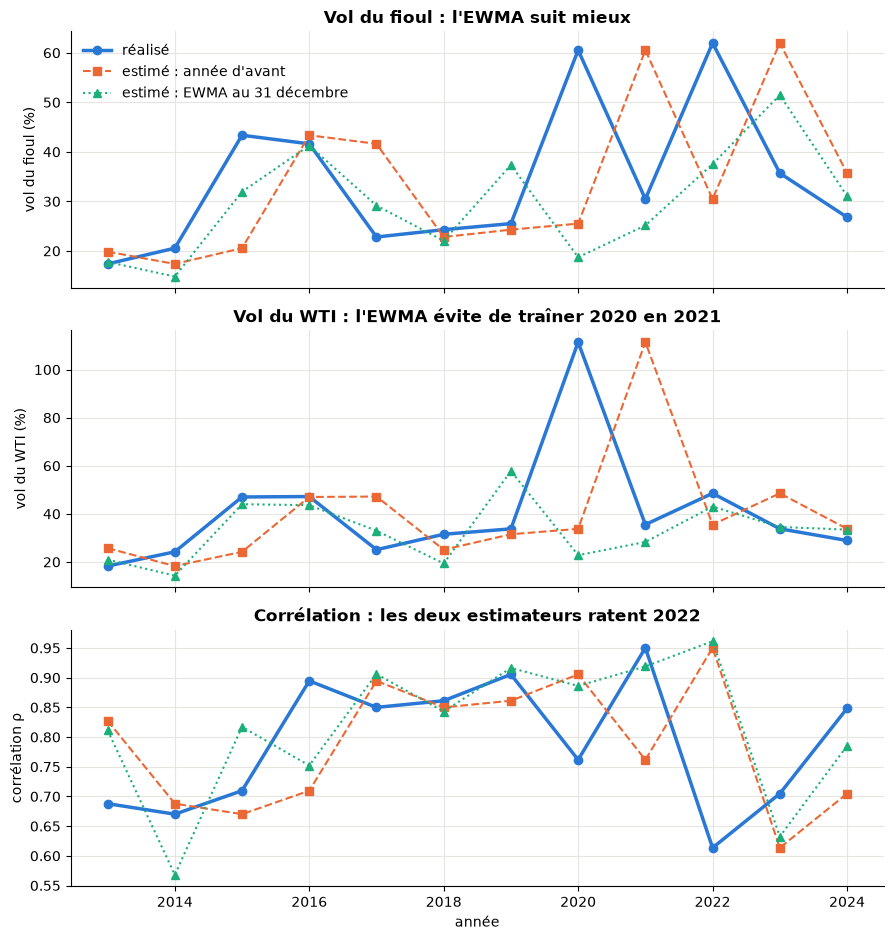

In [9]:
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"  # same colours for the same roles in every panel
fig, axes = plt.subplots(3, 1, figsize=(9, 9.5), sharex=True)
panels = [("sigma1", 100, "vol du fioul (%)", "Vol du fioul : l'EWMA suit mieux"),
          ("sigma2", 100, "vol du WTI (%)", "Vol du WTI : l'EWMA évite de traîner 2020 en 2021"),
          ("rho", 1, "corrélation ρ", "Corrélation : les deux estimateurs ratent 2022")]
for ax, (param, scale, ylabel, title) in zip(axes, panels):
    ax.plot(years, est[param]["real"] * scale, "o-", color=BLUE, linewidth=2.5, label="réalisé")
    ax.plot(years, est[param]["histo"] * scale, "s--", color=ORANGE, label="estimé : année d'avant")
    ax.plot(years, est[param]["ewma"] * scale, "^:", color=AQUA, label="estimé : EWMA au 31 décembre")
    ax.set_ylabel(ylabel)
    ax.set_title(title, fontweight="bold")
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(color="#e6e5e0")
    ax.set_axisbelow(True)
axes[0].legend(frameon=False)
axes[-1].set_xlabel("année")
plt.tight_layout()
plt.show()

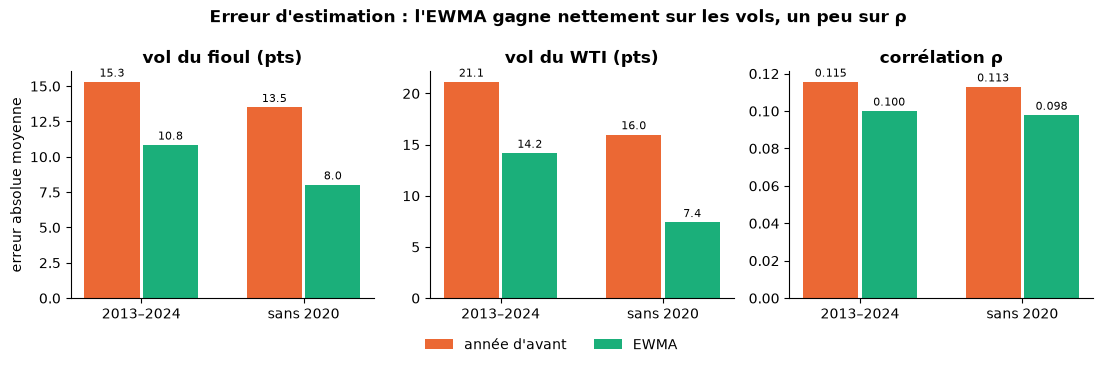

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.6))
titles = {"sigma1": "vol du fioul (pts)", "sigma2": "vol du WTI (pts)", "rho": "corrélation ρ"}
x = np.arange(2)  # two groups: all years, without 2020
for ax, (param, scale) in zip(axes, [("sigma1", 100), ("sigma2", 100), ("rho", 1)]):
    for shift, method, c, name in [(-0.18, "histo", ORANGE, "année d'avant"), (0.18, "ewma", AQUA, "EWMA")]:
        err = np.abs(est[param][method] - est[param]["real"]) * scale
        values = [err.mean(), err[not_2020].mean()]
        bars = ax.bar(x + shift, values, width=0.34, color=c, label=name)
        ax.bar_label(bars, fmt="%.1f" if scale == 100 else "%.3f", fontsize=8, padding=2)  # value on top
    ax.set_xticks(x, ["2013–2024", "sans 2020"])
    ax.set_title(titles[param], fontweight="bold")
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("erreur absolue moyenne")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=2, frameon=False)  # one legend under the 3 panels
fig.suptitle("Erreur d'estimation : l'EWMA gagne nettement sur les vols, un peu sur ρ", fontweight="bold")
plt.tight_layout(rect=(0, 0.07, 1, 1))  # leave room at the bottom for the legend
plt.show()

### Lecture

La corrélation fioul/WTI bouge beaucoup : de 0,61 à 0,95 selon les années. Comme pour la vol du Brent, la courbe historique est la courbe réalisée décalée d'un an. Le pire cas est 2022 : fin 2021 tout annonçait 0,95 (les deux estimateurs), et l'année a donné 0,61. Avec la guerre en Ukraine, le fioul a flambé beaucoup plus que le brut (crack de 23 à 110 \$).

Aucun des deux estimateurs n'a de gros biais sur ρ. L'erreur absolue moyenne est de 0,115 en historique et 0,100 en EWMA, alors qu'un ρ constant serait estimé à ± 0,04 près sur un an (`test_volatility.py`) : ρ change vraiment d'une année à l'autre. L'EWMA est plus proche 7 années sur 12, ce qui ne permet pas de conclure.

Pour les vols, l'EWMA fait nettement mieux, comme pour le Brent, surtout sans 2020 : 8,0 points contre 13,5 pour le fioul, 7,4 contre 16,0 pour le WTI. En 2020, il sous-estime beaucoup (biais négatif), car rien fin 2019 n'annonçait le Covid.

## Ce qu'on retient

- Brent : l'EWMA estime mieux la vol que l'année d'avant (11,7 contre 14,7 points d'erreur).
- Crack : même chose pour les deux vols. Pour ρ, l'EWMA fait un peu mieux (0,100 contre 0,115 d'erreur moyenne), sans que ce soit net.
- L'erreur sur ρ (≈ 0,1) est bien plus grande que le bruit d'estimation (0,04) : ρ change d'une année à l'autre, et ce sera la principale source d'erreur des trades de crack (notebook 3).